# Trabajo Final - CC219 Aplicaciones de Data Science
## Avisos inmobiliarios del Perú: clasificación y predicción a partir del texto

Integrantes:
1. Juan Felipe Granados Allende - U202212216
2. David Miguel Ramos Parihuaman - U202417368
3. Renee Enriquez Montalvan - U202221447

Sección CC92 - Ciclo 2026-2

Objetivo del notebook: cargar, inspeccionar y preparar los avisos inmobiliarios del Perú publicados en Properati (dataset de Kaggle), hacer el análisis exploratorio y entrenar y comparar los modelos que responden las tres preguntas del caso de uso.

Preguntas del caso de uso:
- P1 (clasificación): ¿se puede identificar el tipo de inmueble (departamento, casa, lote, local comercial u oficina) solo con el título y la descripción del aviso, y así reclasificar los avisos registrados como "Otro"?
- P2 (predicción): ¿se puede predecir el segmento de precio (económico, medio o alto) de un departamento en venta en Lima Metropolitana usando el texto del aviso? ¿qué palabras pesan más?
- P3 (predicción): ¿se pueden predecir el número de dormitorios, el número de baños y el área del inmueble a partir del texto, para completar los datos que faltan en los campos?

Dataset: Property Listings for 5 South American Countries (Jacobsen, 2020), archivo pe_properties.csv, datos originales de Properati Data.

## 0. Librerías

La primera celda instala kagglehub, que se usa para bajar los datos. En Colab conviene activar la GPU (Entorno de ejecución > Cambiar tipo de entorno), porque la sección 5 usa embeddings y un LLM.

In [1]:
!pip -q install kagglehub

In [2]:
import os, re, html, json, unicodedata, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10})
SEED = 42
os.makedirs('figs', exist_ok=True)
os.makedirs('data', exist_ok=True)

def guardar(nombre):
    plt.savefig(f'figs/{nombre}.png')

COLORES_TIPO = {'Departamento': '#4C72B0', 'Casa': '#DD8452', 'Lote': '#55A868', 'Local comercial': '#C44E52',
                'Oficina': '#8172B3', 'Otro': '#937860', 'Depósito': '#DA8BC3', 'Minoritarios (PH, cochera, casa de campo)': '#8C8C8C'}
COLORES_SEG = {'económico': '#55A868', 'medio': '#4C72B0', 'alto': '#C44E52'}

## 1. Carga de datos

Se usa kagglehub para bajar solo el archivo de Perú (pe_properties.csv) del dataset público. No pide credenciales. Si el archivo ya está en la carpeta data (por ejemplo, subido a mano o clonado del repositorio de GitHub, donde está comprimido como pe_properties.csv.xz) se lee desde ahí.

In [3]:
ARCHIVO = 'data/pe_properties.csv'
DATASET = 'rmjacobsen/property-listings-for-5-south-american-countries'
locales = [ARCHIVO, 'data/pe_properties.csv.xz', '../data/pe_properties.csv.xz', '../Dataset/pe_properties.csv.xz']
existentes = [p for p in locales if os.path.exists(p)]
if existentes:
    ruta = existentes[0]
else:
    try:
        import kagglehub
        ruta = kagglehub.dataset_download(DATASET, path='pe_properties.csv')
    except Exception as e:
        print('kagglehub falló:', e)
        import requests, zipfile, io
        r = requests.get(f'https://www.kaggle.com/api/v1/datasets/download/{DATASET}/pe_properties.csv', timeout=120)
        zipfile.ZipFile(io.BytesIO(r.content)).extractall('data')
        ruta = ARCHIVO
df_raw = pd.read_csv(ruta)
print('Archivo:', ruta)
print('Filas y columnas:', df_raw.shape)
df_raw.head(3).T

Archivo: data/pe_properties.csv
Filas y columnas: (124449, 25)


,0,1,2
id,OHnwRj8WCByyWFlzr8CG2w==,+r81Zjmgyd2Y+cguWfoHhw==,TP2j5KyjkY1glXvrCBoqkA==
ad_type,Propiedad,Propiedad,Propiedad
start_date,2019-06-25,2019-06-25,2019-06-25
end_date,2019-07-23,2019-12-25,2019-09-03
created_on,2019-06-25,2019-06-25,2019-06-25
lat,-12.094636,-12.094851,-12.071644
lon,-77.003267,-77.017706,-77.037922
l1,Perú,Perú,Perú
l2,Lima,Lima,Lima
l3,Lima,Lima,Lima


## 2. Inspección de los datos

In [4]:
resumen = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'no_nulos': df_raw.notna().sum(),
    'pct_nulos': (df_raw.isna().mean() * 100).round(1),
    'valores_unicos': df_raw.nunique()
})
resumen

,tipo,no_nulos,pct_nulos,valores_unicos
id,str,124449,0.0,124449
ad_type,str,124449,0.0,1
start_date,str,124449,0.0,388
end_date,str,124449,0.0,439
created_on,str,124449,0.0,388
lat,float64,118118,5.1,41878
lon,float64,118118,5.1,41254
l1,str,124449,0.0,1
l2,str,124449,0.0,25
l3,str,119496,4.0,86


In [5]:
for col in ['ad_type', 'l1', 'operation_type', 'property_type', 'currency', 'price_period']:
    print(f'--- {col}')
    print(df_raw[col].value_counts(dropna=False).to_string(), '\n')

--- ad_type
ad_type
Propiedad    124449 

--- l1
l1
Perú    124449 

--- operation_type
operation_type
Venta                90980
Alquiler             33459
Alquiler temporal       10 

--- property_type
property_type
Departamento       51299
Otro               24670
Casa               20750
Lote               12669
Local comercial     8361
Oficina             6010
Depósito             645
PH                    28
Casa de campo         10
Cochera                7 

--- currency
currency
USD    98379
PEN    23028
NaN     3039
ARS        3 

--- price_period
price_period
NaN        65029
Mensual    59420 



In [6]:
print('Rango de fechas de publicación:', df_raw.start_date.min(), 'a', df_raw.start_date.max())
print('Ids repetidos:', df_raw.id.duplicated().sum())
print('Avisos con título y descripción idénticos a otro:', df_raw.duplicated(['title', 'description']).sum())
print('Descripciones vacías:', (df_raw.description.fillna('').str.strip() == '').sum())
print('Avisos sin precio:', df_raw.price.isna().sum())
df_raw[['price', 'surface_total', 'surface_covered', 'bedrooms', 'bathrooms', 'rooms']].describe(
    percentiles=[.01, .5, .99]).round(1)

Rango de fechas de publicación: 2019-03-01 a 2020-03-24
Ids repetidos: 0


Avisos con título y descripción idénticos a otro: 21024
Descripciones vacías: 5
Avisos sin precio: 2397


,price,surface_total,surface_covered,bedrooms,bathrooms,rooms
count,122052.0,80361.0,50549.0,41447.0,87501.0,31989.0
mean,394655.1,740.4,16171.3,3.3,2.8,3.4
std,1807121.9,9561.5,3066074.8,2.4,1.8,2.5
min,0.0,10.0,1.0,0.0,1.0,1.0
1%,400.0,18.0,9.0,0.0,1.0,1.0
50%,118000.0,128.0,125.0,3.0,2.0,3.0
99%,4800000.0,7322.0,12492.3,12.0,10.0,16.0
max,133481430.0,500000.0,687975640.0,50.0,20.0,20.0


Lo que sale de la inspección:
- Son 124 449 avisos de todo el Perú publicados entre marzo de 2019 y marzo de 2020, con 25 columnas. Todos son de tipo Propiedad y del país Perú, así que ad_type y l1 no aportan nada.
- Hay 21 024 avisos que repiten exactamente el mismo título y la misma descripción (el mismo aviso subido varias veces), hay que sacarlos.
- Faltan muchos datos estructurados: dormitorios (66.7 %), área techada (59.4 %), área total (35.4 %) y baños (29.7 %). l5 y l6 están vacías. En cambio el título y la descripción están en casi todos los avisos, por eso el texto termina siendo la fuente más completa.
- Los precios tienen valores raros (mínimo 0 y máximo de 133 millones) y vienen en dos monedas (USD y PEN), así que para analizar precios hay que filtrar por moneda y quitar extremos.

## 3. Preprocesamiento

### 3.1 Limpieza de registros

Pasos: quitar avisos repetidos (mismo título y misma descripción), quitar descripciones vacías, borrar columnas que no aportan (l5 y l6 están vacías, ad_type y l1 tienen un solo valor) y renombrar la ubicación.

In [7]:
pasos = [('Datos originales', len(df_raw))]
df = df_raw.drop_duplicates(subset=['title', 'description']).copy()
pasos.append(('Sin avisos duplicados (título + descripción)', len(df)))
df = df[df.description.fillna('').str.strip().str.len() > 0]
pasos.append(('Sin descripciones vacías', len(df)))

df = df.drop(columns=['l5', 'l6', 'ad_type', 'l1'])
df = df.rename(columns={'l2': 'region', 'l3': 'provincia', 'l4': 'distrito'})
df['start_date'] = pd.to_datetime(df['start_date'])
df['es_lima_metro'] = (df.region == 'Lima') & (df.provincia == 'Lima')
df['tipo'] = df.property_type.replace({'PH': 'Minoritarios (PH, cochera, casa de campo)', 'Cochera': 'Minoritarios (PH, cochera, casa de campo)',
                                       'Casa de campo': 'Minoritarios (PH, cochera, casa de campo)'})
df = df.reset_index(drop=True)
pd.DataFrame(pasos, columns=['paso', 'avisos'])

,paso,avisos
0,Datos originales,124449
1,Sin avisos duplicados (título + descripción),103425
2,Sin descripciones vacías,103423


### 3.2 Normalización de textos

El título y la descripción se juntan en un solo texto. Se generan tres versiones:

- texto: limpieza básica. Se quitan etiquetas HTML, enlaces, correos y teléfonos (anonimización). Es el que lee el LLM de la P3, porque necesita los números tal como están escritos.
- texto_modelo: el anterior con los montos de precio enmascarados con la marca [MONTO], para que los modelos de la P2 no "hagan trampa" leyendo el precio escrito en el aviso. Se mantienen mayúsculas, tildes y signos porque los embeddings sí los aprovechan.
- texto_norm: normalización completa para TF-IDF: minúsculas, sin tildes (se conserva la ñ), unidades de área unificadas como m2, sin signos de puntuación y sin stopwords del español, aunque se conservan "no" y "sin" porque cambian el sentido (sin muebles, no mascotas).

In [8]:
try:
    import nltk
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    STOP_ES = stopwords.words('spanish')
except Exception:
    STOP_ES = '''de la que el en y a los del se las por un para con no una su al lo como más pero sus le ya o este sí porque esta entre cuando muy sin sobre también me hasta hay donde quien desde todo nos durante todos uno les ni contra otros ese eso ante ellos e esto mí antes algunos qué unos yo otro otras otra él tanto esa estos mucho quienes nada muchos cual poco ella estar estas algunas algo nosotros mi mis tú te ti tu tus ellas nosotras vosotros vosotras os mío mía míos mías tuyo tuya tuyos tuyas suyo suya suyos suyas nuestro nuestra nuestros nuestras vuestro vuestra vuestros vuestras esos esas estoy estás está estamos estáis están esté estés estemos estéis estén estaré estarás estará estaremos estaréis estarán estaría estarías estaríamos estaríais estarían estaba estabas estábamos estabais estaban estuve estuviste estuvo estuvimos estuvisteis estuvieron estuviera estuvieras estuviéramos estuvierais estuvieran estuviese estuvieses estuviésemos estuvieseis estuviesen estando estado estada estados estadas estad he has ha hemos habéis han haya hayas hayamos hayáis hayan habré habrás habrá habremos habréis habrán habría habrías habríamos habríais habrían había habías habíamos habíais habían hube hubiste hubo hubimos hubisteis hubieron hubiera hubieras hubiéramos hubierais hubieran hubiese hubieses hubiésemos hubieseis hubiesen habiendo habido habida habidos habidas soy eres es somos sois son sea seas seamos seáis sean seré serás será seremos seréis serán sería serías seríamos seríais serían era eras éramos erais eran fui fuiste fue fuimos fuisteis fueron fuera fueras fuéramos fuerais fueran fuese fueses fuésemos fueseis fuesen sintiendo sentido sentida sentidos sentidas siente sentid tengo tienes tiene tenemos tenéis tienen tenga tengas tengamos tengáis tengan tendré tendrás tendrá tendremos tendréis tendrán tendría tendrías tendríamos tendríais tendrían tenía tenías teníamos teníais tenían tuve tuviste tuvo tuvimos tuvisteis tuvieron tuviera tuvieras tuviéramos tuvierais tuvieran tuviese tuvieses tuviésemos tuvieseis tuviesen teniendo tenido tenida tenidos tenidas tened'''.split()

def quitar_tildes(t):
    t = t.replace('ñ', '#enie#').replace('Ñ', '#ENIE#')
    t = unicodedata.normalize('NFKD', t).encode('ascii', 'ignore').decode('ascii')
    return t.replace('#enie#', 'ñ').replace('#ENIE#', 'Ñ')

STOP = {quitar_tildes(w) for w in STOP_ES} - {'no', 'sin'}
print('Stopwords en español:', len(STOP))

PAT_HTML = re.compile(r'<[^>]+>')
PAT_URL = re.compile(r'(?:https?://\S+|www\.\S+)', re.I)
PAT_EMAIL = re.compile(r'[\w.+-]+@[\w-]+\.[\w.]+')
PAT_TEL = re.compile(r'(?:\+?51[\s.-]?)?\b9\d{2}[\s.-]?\d{3}[\s.-]?\d{3}\b|\(?\b0?1\)?[\s.-]?\d{3}[\s.-]\d{4}\b|\b\d{3}[\s.-]\d{4}\b')
PAT_MONTO = re.compile(r'(?:us\s?\$|u\$s|\$|usd|s/\.?|s/)\s*\d[\d.,]*(?:\s?(?:mil|k)\b)?'
                       r'|\d[\d.,]*\s*(?:mil\s*)?(?:d[oó]lares|soles|usd)\b', re.I)
PAT_NUM_GRANDE = re.compile(r'\b\d{1,3}(?:[.,]\d{3})+(?:[.,]\d+)?\b|\b\d{5,}\b')

def limpiar_basico(t):
    t = html.unescape(str(t))
    t = PAT_HTML.sub(' ', t)
    t = PAT_URL.sub(' ', t)
    t = PAT_EMAIL.sub(' ', t)
    t = PAT_TEL.sub(' ', t)
    return re.sub(r'\s+', ' ', t).strip()

def enmascarar_montos(t):
    t = PAT_MONTO.sub(' [MONTO] ', t)
    t = PAT_NUM_GRANDE.sub(' [MONTO] ', t)
    return re.sub(r'\s+', ' ', t).strip()

def normalizar(t):
    t = quitar_tildes(t.lower())
    t = t.replace('[monto]', ' ')
    t = re.sub(r'(\d+)[.,]0\b', r'\1', t)
    t = re.sub(r'(\d)\s*(?:m2|mts2|mt2|mtrs2|mts|mt|metros cuadrados)\b', r'\1 m2', t)
    t = re.sub(r'\bmetros cuadrados\b', ' m2 ', t)
    t = re.sub(r'[^a-zñ0-9 ]', ' ', t)
    return ' '.join(w for w in t.split() if w not in STOP and (len(w) > 1 or w.isdigit()))

Stopwords en español: 304


In [9]:
t0 = time.time()
texto_crudo = df.title.fillna('') + '. ' + df.description.fillna('')

stats_texto = {
    'Avisos con etiquetas HTML': texto_crudo.str.contains(PAT_HTML).mean(),
    'Avisos con teléfono': texto_crudo.str.contains(PAT_TEL).mean(),
    'Avisos con correo': texto_crudo.str.contains(PAT_EMAIL).mean(),
    'Avisos que escriben un monto de dinero': texto_crudo.str.contains(PAT_MONTO).mean(),
}
print(pd.Series(stats_texto).mul(100).round(1).astype(str) + ' %')

df['texto'] = texto_crudo.map(limpiar_basico)
df['texto_modelo'] = df['texto'].map(enmascarar_montos)
df['texto_norm'] = df['texto_modelo'].map(normalizar)
df['n_palabras'] = df['texto'].str.split().str.len()
print(f'Normalización lista en {time.time() - t0:.0f} s')

vocab_antes = Counter(w for t in df['texto'].sample(5000, random_state=SEED) for w in t.split())
vocab_despues = Counter(w for t in df['texto_norm'].sample(5000, random_state=SEED) for w in t.split())
print('Tamaño del vocabulario en una muestra de 5000 avisos: antes', len(vocab_antes), '| después', len(vocab_despues))

Avisos con etiquetas HTML                 28.5 %
Avisos con teléfono                       10.4 %
Avisos con correo                          0.1 %
Avisos que escriben un monto de dinero    35.2 %
dtype: str


Normalización lista en 27 s
Tamaño del vocabulario en una muestra de 5000 avisos: antes 47928 | después 14905


In [10]:
cond = (df.n_palabras.between(40, 90) & df.es_lima_metro & texto_crudo.str.contains(PAT_HTML)
        & texto_crudo.str.contains(PAT_TEL) & texto_crudo.str.contains(PAT_MONTO))
ej = df[cond].sample(1, random_state=3)
for i, r in ej.iterrows():
    original = PAT_TEL.sub(lambda m: re.sub(r'\d', 'X', m.group()), texto_crudo[i])
    print('ORIGINAL:    ', original[:700], '\n')
    print('TEXTO_MODELO:', r.texto_modelo[:700], '\n')
    print('TEXTO_NORM:  ', r.texto_norm[:700])

ORIGINAL:     VENTA DE CASA COMO TERRENO EN COMAS. SE VENDE CASITA como TERRENO en COMAS (XXXXXXXXX)<br>Papeles en Regla (luz/agua/desague instalados).<br>AT  90 M2, Linderos: 8.97 ML de Frente x 10.40 ML de Largo. <br>Ubicado en Pueblo Joven Señor de Los Milagros, Jiron Cajatambo, zona 100% urbanizada, hay gas natural, a 1 cuadra de línea del Metropolitano. A 3 cuadras de la Av. Belaunde Este, a 4 min de Av. Tupac Amaru, cerca a Colegios, Mercados, Super Mercados, clínicas, Bancos, etc.<br>PRECIO : S/. 85,000 

TEXTO_MODELO: VENTA DE CASA COMO TERRENO EN COMAS. SE VENDE CASITA como TERRENO en COMAS ( ) Papeles en Regla (luz/agua/desague instalados). AT 90 M2, Linderos: 8.97 ML de Frente x 10.40 ML de Largo. Ubicado en Pueblo Joven Señor de Los Milagros, Jiron Cajatambo, zona 100% urbanizada, hay gas natural, a 1 cuadra de línea del Metropolitano. A 3 cuadras de la Av. Belaunde Este, a 4 min de Av. Tupac Amaru, cerca a Colegios, Mercados, Super Mercados, clínicas, Bancos, etc. PRECIO :

En el ejemplo se ven los tres cambios: se van las etiquetas HTML y el teléfono (en el original se muestra con X), el precio pasa a [MONTO] y en texto_norm quedan solo las palabras que sirven para TF-IDF.

### 3.3 Variables derivadas del texto: reglas de extracción

Muchos avisos escriben en la descripción datos que no llenaron en los campos (dormitorios, baños y área). Estas reglas con expresiones regulares son la línea base de la P3 y además se marcan las amenidades que se mencionan (piscina, cochera, vista al mar, etc.), que se usan en el EDA.

Las reglas tienen en cuenta cómo escriben los anunciantes:
- números con separador de miles (1,200 m2 o 1.200 m2) y números escritos en palabras (tres dormitorios);
- el número antes o después de la palabra (3 dormitorios, dormitorios: 3);
- el medio baño y el baño de visita se cuentan como un baño más (2 y medio baños = 3); los baños y cuartos de servicio no se cuentan;
- dormitorio principal + 2 dormitorios secundarios = 3;
- el área se separa en techada y de terreno cuando el texto las distingue, y no se toman distancias (a 100 mts del parque), precios por m2 ni áreas de una parte del inmueble (terraza de 20 m2);
- si el aviso da números distintos (por ejemplo un proyecto con departamentos de 2 y 3 dormitorios) no se adivina y el dato queda vacío.

In [11]:
NUM_PAL = {'un': 1, 'uno': 1, 'una': 1, 'dos': 2, 'tres': 3, 'cuatro': 4, 'cinco': 5,
           'seis': 6, 'siete': 7, 'ocho': 8, 'nueve': 9, 'diez': 10}

def preparar_extraccion(t):
    t = t.replace('ñ', 'n').replace('½', ' 1/2 ')
    t = re.sub(r'(?<=\d)[.,](?=\d{3}\b)', '', t)
    t = re.sub(r'\b(' + '|'.join(NUM_PAL) + r')\b', lambda m: str(NUM_PAL[m.group(1)]), t)
    t = re.sub(r'(?<=\d)\s*(?:m2|m\.2|mt2|mts2|mts\.2|mtrs2|mtr2|metros? cuadrados?|metros?2)(?![a-z0-9])', ' m2', t)
    return re.sub(r'\s+', ' ', t)

RANGO = re.compile(r'\b\d{1,2}\s*(?:,\s*\d{1,2}\s*)*(?:a|al|y|o|-)\s*$')

def es_rango(t, inicio):
    return bool(RANGO.search(t[max(0, inicio - 14):inicio]))

def valor_unico(valores):
    return valores[0] if valores and len(set(valores)) == 1 else np.nan

DORM = r'(?:dormitorios?|dorms?\b\.?|habitaciones?|hab\b\.?|cuartos?|recamaras?)'
PAT_DORM = re.compile(r'(\botr[oa]s\s+)?\b(\d{1,2})\s*(?:(?:amplios?|amplias?|comodos?|comodas?|grandes?|buenos?|lindos?|lindas?)\s+)?' + DORM
                      + r'(?!\s*(?:de|para) (?:servicio|huespedes)|\s+principal)(\s+(?:secundari\w*|adicional\w*|mas\b|simples?))?')
PAT_DORM_DESPUES = re.compile(r'\b(?:dormitorios|habitaciones)\s*[:=-]?\s*(\d{1,2})\b(?!\s*(?:m2|x\b|pisos?|\d))')
PAT_PRINCIPAL = re.compile(r'(?:dormitorio|habitacion|cuarto|recamara|suite) principal|\bmaster\b')

def dormitorios_txt(t):
    principal = PAT_PRINCIPAL.search(t)
    valores = []
    for m in PAT_DORM.finditer(t):
        if es_rango(t, m.start(2)):
            continue
        n = int(m.group(2))
        if principal and (m.group(1) or m.group(3) or principal.start() < m.start()):
            n += 1
        valores.append((m.start(), n))
    valores += [(m.start(), int(m.group(1))) for m in PAT_DORM_DESPUES.finditer(t)]
    return valor_unico([v for _, v in sorted(valores) if 0 < v <= 20])

PAT_BANO = re.compile(r'\b(\d{1,2})(\s*(?:y medio|1/2))?\s*banos?\b(?!\s*(?:completos?\s*)?(?:de |para )?(?:servicio|visitas?|social))'
                      r'(?:\s*(?:completos?|full))?(\s*y medio)?')
PAT_BANO_DESPUES = re.compile(r'\bbanos\s*[:=-]?\s*(\d{1,2})(\s*(?:y medio|1/2))?\b(?!\s*(?:m2|x\b|pisos?|dorm|hab|\d))')
PAT_VISITA = re.compile(r'medio bano|1/2 bano|bano de visitas?|bano para visitas?|bano social|toilette')
PAT_Y_MEDIO = re.compile(r'\d\s*(?:y medio|1/2)\s*banos?|\d\s*banos?\s*(?:completos?\s*)?y medio')

def banos_txt(t):
    valores = []
    for m in PAT_BANO.finditer(t):
        if es_rango(t, m.start(1)):
            continue
        medio = bool(m.group(2) or m.group(3))
        valores.append((m.start(), int(m.group(1)) + medio))
    for m in PAT_BANO_DESPUES.finditer(t):
        valores.append((m.start(), int(m.group(1)) + bool(m.group(2))))
    valores = [v for _, v in sorted(valores) if 0 < v <= 20]
    if valores and PAT_VISITA.search(t) and not PAT_Y_MEDIO.search(t):
        valores = [v + 1 for v in valores]
    return valor_unico(valores)

In [12]:
TECHADA = r'techad\w*|construid\w*|construccion|edificad\w*|ocupad\w*|cubiert\w*|area util'
TERRENO = r'terreno|lote\b|total\w*|superficie|hectareas?'
PARCIAL = r'terrazas?|jardin\w*|balcon\w*|cochera|estacionamiento|patio|deposito|azotea|area libre|aires|mezzanine|sotano'
PAT_CLAVE = re.compile(f'({TECHADA})|({TERRENO})|({PARCIAL})')
PAT_DESPUES = re.compile(r'\s*(?:de\s+(?:area\s+(?:de\s+)?)?)?(?:(techad\w*|construid\w*|edificad\w*|ocupad\w*|cubiert\w*)'
                         r'|(terreno|lote\b|total\w*)|(terrazas?|jardin\w*|balcon\w*|cochera|patio|azotea|libres?\b))')
PAT_M2 = re.compile(r'(?<!\d)(?<!\d[.,])(\d{2,7}(?:[.,]\d{1,2})?)\s*m2\b')
PAT_MTS = re.compile(r'(?<!\d)(?<!\d[.,])(\d{2,7}(?:[.,]\d{1,2})?)\s*(?:mts|mt|mtrs|metros)\b\.?'
                     r'(?!\s*(?:de (?:altura|alto|frente|fondo|ancho|largo|distancia)|lineales|del?\b|de la|de los|de las|hacia|desde))')
PAT_HA = re.compile(r'\b(\d{1,4}(?:[.,]\d{1,2})?)\s*(?:hectareas?|has?\b)')
PAT_DIM = re.compile(r'\b(\d{1,3}(?:[.,]\d{1,2})?)\s*(?:m|mts|ml|metros)?\s*x\s*(\d{1,3}(?:[.,]\d{1,2})?)\s*(?:m2|m|mts|ml|metros)\b')
PAT_DISTANCIA = re.compile(r'\ba (?:solo |unos |menos de |mas de )?$')
PAT_PRECIO = re.compile(r'(?:\$|us|usd|s/|soles|dolares|precio|valor)\s*\.?:?\s*$')
PAT_RANGO_AREA = re.compile(r'(?:desde|hasta|entre)\s*$|\b\d{2,5}\s*(?:m2\s*)?(?:a|al|y|-)\s*$')

def tipo_area(antes, despues):
    m = PAT_DESPUES.match(despues)
    if m is None:
        claves = list(PAT_CLAVE.finditer(antes))
        m = claves[-1] if claves else None
        if m is not None and m.group(3) and len(antes) - m.end() > 12:
            m = next((c for c in reversed(claves) if not c.group(3)), None)
    if m is None:
        return 'general'
    return 'techada' if m.group(1) else ('terreno' if m.group(2) else 'parcial')

def areas_txt(t):
    encontradas = []
    for pat in (PAT_M2, PAT_MTS):
        for m in pat.finditer(t):
            antes, despues = t[max(0, m.start() - 30):m.start()], t[m.end():m.end() + 25]
            if PAT_PRECIO.search(antes[-12:]) or PAT_RANGO_AREA.search(antes[-14:]):
                continue
            if pat is PAT_MTS and PAT_DISTANCIA.search(antes[-12:]):
                continue
            encontradas.append((m.start(), tipo_area(antes, despues), float(m.group(1).replace(',', '.'))))
    for m in PAT_HA.finditer(t):
        encontradas.append((m.start(), 'terreno', float(m.group(1).replace(',', '.')) * 10000))
    encontradas = [e for e in sorted(encontradas) if 10 <= e[2] <= 5e6 and e[1] != 'parcial']
    if not encontradas:
        for m in PAT_DIM.finditer(t):
            a, b = float(m.group(1).replace(',', '.')), float(m.group(2).replace(',', '.'))
            if 3 <= a <= 300 and 3 <= b <= 300:
                encontradas.append((m.start(), 'terreno', a * b))
    primera = lambda tipos: next((v for _, tp, v in encontradas if tp in tipos), np.nan)
    return primera({'general', 'techada', 'terreno'}), primera({'techada'}), primera({'terreno'})

def extraer_atributos(texto_min):
    t = preparar_extraccion(texto_min)
    return (dormitorios_txt(t), banos_txt(t)) + areas_txt(t)

In [13]:
t0 = time.time()
texto_min = df['texto'].str.lower().map(quitar_tildes)
extraido = pd.DataFrame(texto_min.map(extraer_atributos).tolist(), index=df.index,
                        columns=['dorm_txt', 'banos_txt', 'area_txt', 'area_techada_txt', 'area_terreno_txt'])
for c in extraido.columns:
    df[c] = extraido[c]

AMENIDADES = {
    'piscina': r'piscina', 'gimnasio': r'gimnasio|\bgym\b', 'ascensor': r'ascensor',
    'cochera o estacionamiento': r'cochera|estacionamiento', 'terraza': r'terraza',
    'vista al mar / malecón': r'vista al mar|frente al mar|vista mar|malecon', 'estreno': r'estreno|estrenar',
    'zona de parrilla': r'parrilla', 'vigilancia': r'vigilancia|seguridad 24|conserjeria|conserje',
    'amoblado': r'amoblad|amueblad', 'jardín': r'jardin', 'áreas comunes': r'areas? comunes',
}
for nombre, patron in AMENIDADES.items():
    df['am_' + nombre] = texto_min.str.contains(patron, regex=True)
print(f'Extracción lista en {time.time() - t0:.0f} s')
print('Avisos con el dato en el texto (%):')
print((extraido.notna().mean() * 100).round(1).to_string())

Extracción lista en 24 s
Avisos con el dato en el texto (%):
dorm_txt            40.8
banos_txt           39.2
area_txt            58.1
area_techada_txt     9.0
area_terreno_txt    19.1


In [14]:
casos = [
    ('3 dormitorios, 2 baños, 120 m2', 3, 2, 120),
    ('Terreno de 1,200 m2', None, None, 1200),
    ('Habitaciones: 3, baños: 2', 3, 2, None),
    ('2 y medio baños', None, 3, None),
    ('3 baños de servicio', None, None, None),
    ('Área construida 120 m2 y terreno 200 m2', None, None, 120),
    ('Dormitorio principal con baño y 2 dormitorios adicionales', 3, None, None),
    ('Departamento a 100 mts del parque Kennedy, 85 m2', None, None, 85),
    ('Casa con 2 baños completos y baño de visita', None, 3, None),
    ('Precio por m2 US$ 1,500. Área 95 m2', None, None, 95),
    ('Lote de 2.500 m2 en Lurín', None, None, 2500),
    ('Tres dormitorios y dos baños y medio', 3, 3, None),
    ('Proyecto con departamentos de 1, 2 y 3 dormitorios', None, None, None),
    ('Terraza de 20 m2 y departamento de 90 m2', None, None, 90),
    ('Terreno de 10 x 20 m en Pachacamac', None, None, 200),
    ('1 baño completo de servicio y 2 baños', None, 2, None),
]
filas = []
for texto, d, b, a in casos:
    r = extraer_atributos(quitar_tildes(texto.lower()))
    obtenido = [None if pd.isna(x) else x for x in r[:3]]
    filas.append({'texto': texto, 'esperado (dorm, baños, área)': (d, b, a), 'obtenido': tuple(obtenido),
                  'techada / terreno': (r[3], r[4]), 'ok': obtenido == [d, b, a]})
prueba = pd.DataFrame(filas)
print('Casos correctos:', prueba.ok.sum(), 'de', len(prueba))
prueba

Casos correctos: 16 de 16


,texto,"esperado (dorm, baños, área)",obtenido,techada / terreno,ok
0,"3 dormitorios, 2 baños, 120 m2","(3, 2, 120)","(3, 2, 120.0)","(nan, nan)",True
1,"Terreno de 1,200 m2","(None, None, 1200)","(None, None, 1200.0)","(nan, 1200.0)",True
2,"Habitaciones: 3, baños: 2","(3, 2, None)","(3, 2, None)","(nan, nan)",True
3,2 y medio baños,"(None, 3, None)","(None, 3, None)","(nan, nan)",True
4,3 baños de servicio,"(None, None, None)","(None, None, None)","(nan, nan)",True
5,Área construida 120 m2 y terreno 200 m2,"(None, None, 120)","(None, None, 120.0)","(120.0, 200.0)",True
6,Dormitorio principal con baño y 2 dormitorios adicionales,"(3, None, None)","(3, None, None)","(nan, nan)",True
7,"Departamento a 100 mts del parque Kennedy, 85 m2","(None, None, 85)","(None, None, 85.0)","(nan, nan)",True
8,Casa con 2 baños completos y baño de visita,"(None, 3, None)","(None, 3, None)","(nan, nan)",True
9,"Precio por m2 US$ 1,500. Área 95 m2","(None, None, 95)","(None, None, 95.0)","(nan, nan)",True


Los 16 casos difíciles salen bien: 1,200 m2, dormitorios: 3 con el número después, 2 y medio baños, baños de servicio, área construida y terreno en el mismo aviso, dormitorio principal más dormitorios adicionales y distancias como a 100 mts del parque. Cuando el aviso da números distintos (por ejemplo un proyecto con departamentos de 1, 2 y 3 dormitorios) el dato queda vacío para no inventarlo.

In [15]:
def comparar_con_campos(d, dorm, banos, area):
    filas = []
    for campo, ext, nombre in [('bedrooms', dorm, 'Dormitorios'), ('bathrooms', banos, 'Baños'), ('surface_total', area, 'Área (m²)')]:
        falta = d[campo].isna()
        ambos = d[campo].notna() & ext.notna()
        if campo == 'surface_total':
            ok = ((d.surface_total - ext).abs() <= 0.05 * d.surface_total) | ((d.surface_covered - ext).abs() <= 0.05 * d.surface_covered)
        else:
            ok = d[campo] == ext
        filas.append({'campo': nombre, 'faltante en el campo (%)': falta.mean() * 100,
                      'de esos, el texto lo menciona (%)': ext[falta].notna().mean() * 100,
                      'coincidencia texto vs campo (%)': ok[ambos].mean() * 100, 'avisos comparados': ambos.sum()})
    return pd.DataFrame(filas).set_index('campo')

base_p3 = df[df.property_type.isin(['Departamento', 'Casa', 'Otro'])]
info = comparar_con_campos(base_p3, base_p3.dorm_txt, base_p3.banos_txt, base_p3.area_txt)
info.round(1)

,faltante en el campo (%),"de esos, el texto lo menciona (%)",coincidencia texto vs campo (%),avisos comparados
campo,,,,
Dormitorios,61.0,44.6,83.4,19319
Baños,20.8,19.3,58.9,32817
Área (m²),31.8,64.9,84.8,28245


En el área se acepta una diferencia de hasta 5 % con el área total o con la techada, porque muchos avisos redondean. Esta tabla se grafica en la Figura 8.

### 3.4 Subconjuntos para cada pregunta

Para la P1 también se marca, en los avisos "Otro", el primer tipo de inmueble que se menciona en el título (o en la descripción si el título no dice nada). Sirve para ver qué hay dentro de esa categoría y para revisar las predicciones del modelo. Para la P2 se toman los departamentos en venta de Lima Metropolitana con precio en dólares, sin el 1 % más barato ni el 1 % más caro, y se dividen en tres segmentos con los terciles del precio.

In [16]:
CLASES_P1 = ['Departamento', 'Casa', 'Lote', 'Local comercial', 'Oficina']
df_p1 = df[df.property_type.isin(CLASES_P1)].copy()
df_otro = df[df.property_type == 'Otro'].copy()

CLAVES = {
    'Terreno / lote': r'terreno|lote|hectarea|parcela|aires|chacra|fundo',
    'Departamento': r'departamento|dpto|depa\b|duplex|flat|penthouse|minidepartamento',
    'Casa': r'\bcasa|chalet|casona|residencia|villa',
    'Local comercial': r'local|tienda|stand|galeria|restaurante',
    'Oficina': r'oficina|consultorio',
    'Habitación / cuarto': r'habitacion|cuarto',
    'Edificio / hotel': r'edificio|hotel|hostal|quinta',
    'Almacén / cochera': r'almacen|deposito|nave|galpon|cochera|estacionamiento|taller',
}
def primera_clave(t):
    mejor, pos = 'Sin palabra clave', 10**9
    for nombre, patron in CLAVES.items():
        m = re.search(patron, t)
        if m and m.start() < pos:
            mejor, pos = nombre, m.start()
    return mejor

df_otro['clave_titulo'] = df_otro.title.fillna('').str.lower().map(quitar_tildes).map(primera_clave)
sin = df_otro.clave_titulo == 'Sin palabra clave'
df_otro.loc[sin, 'clave_titulo'] = texto_min[df_otro.index[sin]].map(primera_clave)

p2 = df[df.es_lima_metro & (df.property_type == 'Departamento') & (df.operation_type == 'Venta') &
        (df.currency == 'USD') & df.price.notna()].copy()
lo, hi = p2.price.quantile([0.01, 0.99])
df_p2 = p2[(p2.price >= lo) & (p2.price <= hi)].copy()
q1, q2 = df_p2.price.quantile([1/3, 2/3])
df_p2['segmento'] = pd.cut(df_p2.price, [-np.inf, q1, q2, np.inf], labels=['económico', 'medio', 'alto'])
area = df_p2.surface_covered.where(df_p2.surface_covered.between(20, 1000), df_p2.surface_total)
df_p2['area_m2'] = area.where(area.between(20, 1000))
df_p2['usd_m2'] = df_p2.price / df_p2.area_m2
df.loc[df_p2.index, 'segmento_precio'] = df_p2['segmento'].astype(str)

print('P1 - avisos con tipo conocido:', len(df_p1), '| avisos "Otro":', len(df_otro))
print(f'P2 - departamentos en venta (Lima, USD): {len(df_p2)} | cortes de los terciles: {q1:,.0f} y {q2:,.0f} USD')
print(df_p2.segmento.value_counts().to_string())

P1 - avisos con tipo conocido: 81754 | avisos "Otro": 21077
P2 - departamentos en venta (Lima, USD): 22509 | cortes de los terciles: 125,000 y 235,000 USD
segmento
económico    7676
alto         7447
medio        7386


## 4. Visualización de los datos

Se dejan los gráficos que se usan en el informe, con la misma numeración (Figura 1 a Figura 8).

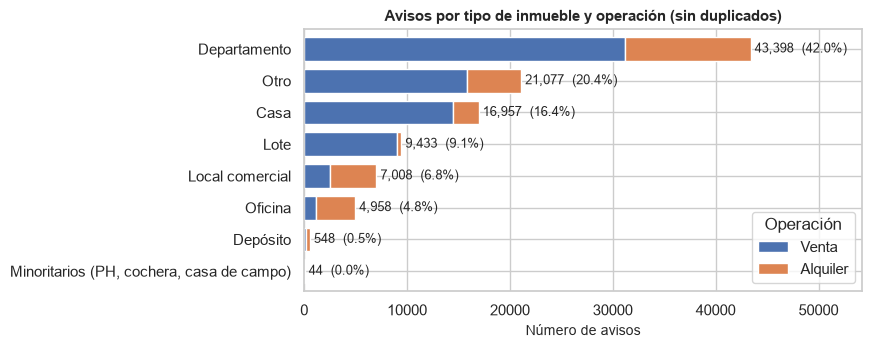

In [17]:
tab = pd.crosstab(df.tipo, df.operation_type.replace({'Alquiler temporal': 'Alquiler'}))
tab = tab.loc[tab.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(7.2, 3.4))
tab[['Venta', 'Alquiler']].plot.barh(stacked=True, ax=ax, color=['#4C72B0', '#DD8452'], width=0.75)
for i, total in enumerate(tab.sum(axis=1)):
    ax.text(total + 400, i, f'{total:,}  ({total / len(df):.1%})', va='center', fontsize=9)
ax.set(xlim=(0, tab.sum(axis=1).max() * 1.25), xlabel='Número de avisos', ylabel='',
       title='Avisos por tipo de inmueble y operación (sin duplicados)')
ax.legend(title='Operación', loc='lower right')
guardar('fig1_tipos'); plt.show()

Casi la mitad de los avisos son departamentos (42 %) y lo que más llama la atención es que 1 de cada 5 avisos (20.4 %) está como "Otro". Es la segunda categoría más grande, o sea que si alguien filtra por tipo de inmueble se pierde más de 21 mil avisos. Esto es lo que motiva la P1. También se ve que casi todo es venta, menos oficinas y locales comerciales que son más de alquiler.

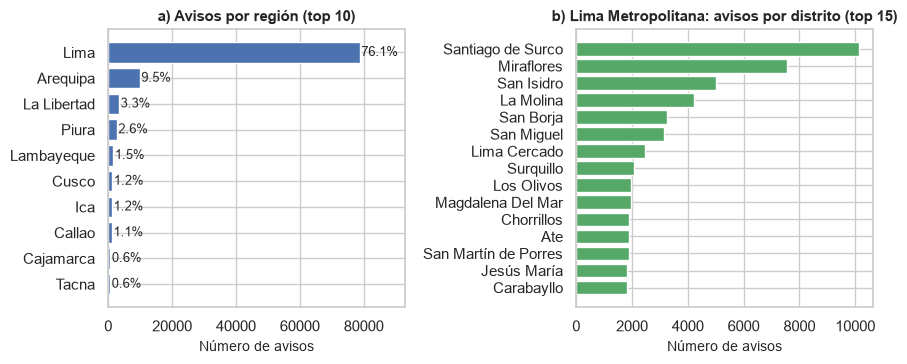

Lima Metropolitana: 74334 avisos (71.9%) | distritos: 43


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
reg = df.region.value_counts().head(10).sort_values()
axes[0].barh(reg.index, reg.values, color='#4C72B0')
for i, v in enumerate(reg.values):
    axes[0].text(v + 500, i, f'{v / len(df):.1%}', va='center', fontsize=9)
axes[0].set(xlim=(0, reg.max() * 1.18), title='a) Avisos por región (top 10)', xlabel='Número de avisos')
dist = df[df.es_lima_metro].distrito.value_counts().head(15).sort_values()
axes[1].barh(dist.index, dist.values, color='#55A868')
axes[1].set(title='b) Lima Metropolitana: avisos por distrito (top 15)', xlabel='Número de avisos')
plt.tight_layout(); guardar('fig2_geografia'); plt.show()
print('Lima Metropolitana:', df.es_lima_metro.sum(), f'avisos ({df.es_lima_metro.mean():.1%})', '| distritos:', df[df.es_lima_metro].distrito.nunique())

El dataset está muy concentrado en Lima: 76 % de los avisos son de la región Lima y 72 % de Lima Metropolitana (43 distritos). Arequipa es la segunda con 9.5 %. Dentro de Lima, Santiago de Surco, Miraflores y San Isidro son los distritos con más avisos. Por eso la P2 se trabaja solo con Lima Metropolitana, que es donde hay datos suficientes.

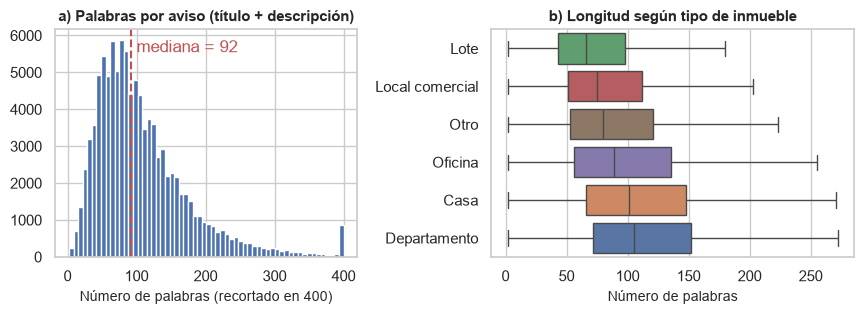

count    103423.0
mean        109.2
std          74.3
min           2.0
25%          61.0
50%          92.0
75%         138.0
max        2547.0


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(8.8, 3.3), gridspec_kw={'width_ratios': [1, 1.2]})
med = df.n_palabras.median()
axes[0].hist(df.n_palabras.clip(upper=400), bins=60, color='#4C72B0')
axes[0].axvline(med, color='#C44E52', ls='--')
axes[0].text(med + 8, axes[0].get_ylim()[1] * 0.9, f'mediana = {med:.0f}', color='#C44E52')
axes[0].set(title='a) Palabras por aviso (título + descripción)', xlabel='Número de palabras (recortado en 400)')
orden = df[df.tipo.isin(CLASES_P1 + ['Otro'])].groupby('tipo').n_palabras.median().sort_values().index
sns.boxplot(data=df[df.tipo.isin(orden)], y='tipo', x='n_palabras', order=orden, showfliers=False, ax=axes[1],
            palette=[COLORES_TIPO[t] for t in orden])
axes[1].set(title='b) Longitud según tipo de inmueble', xlabel='Número de palabras', ylabel='')
plt.tight_layout(); guardar('fig3_longitud'); plt.show()
print(df.n_palabras.describe().round(1).to_string())

La mitad de los avisos tiene entre 61 y 138 palabras (mediana de 92), son textos cortos pero con bastante información. Hay pocos muy largos (hasta 2547 palabras), que el modelo de embeddings y el LLM igual van a cortar. Los departamentos y las casas tienen descripciones más largas que los lotes, tiene sentido porque describen ambientes y acabados.

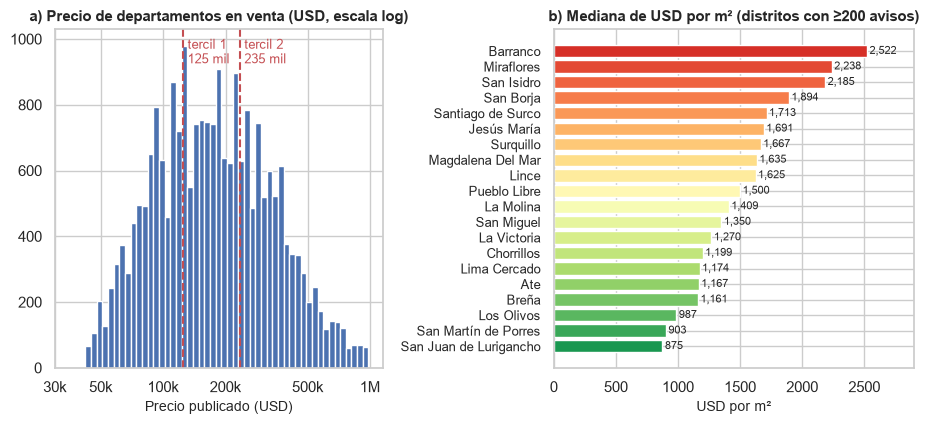

count     22509.0
mean     216712.0
std      155159.0
min       42000.0
25%      108000.0
50%      170000.0
75%      280000.0
max      980000.0
Más caro: Barranco 2522 | más barato: San Juan de Lurigancho 875


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.4), gridspec_kw={'width_ratios': [1, 1.1]})
axes[0].hist(np.log10(df_p2.price), bins=50, color='#4C72B0')
for q, nombre in [(q1, 'tercil 1'), (q2, 'tercil 2')]:
    axes[0].axvline(np.log10(q), color='#C44E52', ls='--')
    axes[0].text(np.log10(q) + 0.02, axes[0].get_ylim()[1] * 0.9, f'{nombre}\n{q / 1000:,.0f} mil', color='#C44E52', fontsize=9)
ticks = [30000, 50000, 100000, 200000, 500000, 1000000]
axes[0].set_xticks(np.log10(ticks), ['30k', '50k', '100k', '200k', '500k', '1M'])
axes[0].set(title='a) Precio de departamentos en venta (USD, escala log)', xlabel='Precio publicado (USD)')

m2 = df_p2[df_p2.usd_m2.between(300, 8000)]
cnt = m2.distrito.value_counts()
top = m2[m2.distrito.isin(cnt[cnt >= 200].index)].groupby('distrito').usd_m2.median().sort_values()
axes[1].barh(top.index, top.values, color=plt.cm.RdYlGn_r(np.linspace(0.1, 0.9, len(top))))
for i, v in enumerate(top.values):
    axes[1].text(v + 20, i, f'{v:,.0f}', va='center', fontsize=8)
axes[1].set(title='b) Mediana de USD por m² (distritos con ≥200 avisos)', xlabel='USD por m²', xlim=(0, top.max() * 1.15))
axes[1].tick_params(axis='y', labelsize=9)
plt.tight_layout(); guardar('fig4_precios'); plt.show()
print(df_p2.price.describe().round(0).to_string())
print('Más caro:', top.idxmax(), round(top.max()), '| más barato:', top.idxmin(), round(top.min()))

Los precios de departamentos en venta se ven mejor en escala logarítmica, la mediana está en 170 mil dólares. Los terciles cortan en 125 mil y 235 mil dólares, esos son los límites de los segmentos económico, medio y alto. El precio por m² cambia muchísimo según el distrito: Barranco, Miraflores y San Isidro pasan los 2 mil dólares por m² y San Juan de Lurigancho, San Martín de Porres y Los Olivos están por debajo de mil, casi tres veces menos. Entonces el distrito que se menciona en el texto debería ayudar bastante a predecir el segmento.

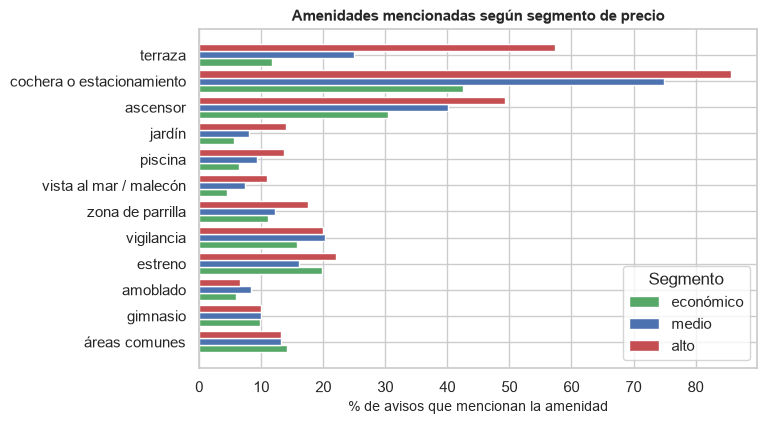

segmento,económico,medio,alto
áreas comunes,14.1,13.2,13.2
gimnasio,9.8,9.9,10.0
amoblado,5.9,8.4,6.6
estreno,19.7,16.1,22.1
vigilancia,15.7,20.3,20.0
zona de parrilla,11.1,12.2,17.5
vista al mar / malecón,4.4,7.4,11.0
piscina,6.5,9.3,13.6
jardín,5.5,8.0,14.1
ascensor,30.4,40.0,49.3


In [21]:
am = df_p2.groupby('segmento')[['am_' + a for a in AMENIDADES]].mean().T * 100
am.index = list(AMENIDADES)
am = am.loc[(am['alto'] - am['económico']).sort_values().index]
fig, ax = plt.subplots(figsize=(7.2, 4.4))
y = np.arange(len(am))
for k, seg in enumerate(['económico', 'medio', 'alto']):
    ax.barh(y + (k - 1) * 0.27, am[seg], height=0.27, color=COLORES_SEG[seg], label=seg)
ax.set_yticks(y, am.index)
ax.set(xlabel='% de avisos que mencionan la amenidad', title='Amenidades mencionadas según segmento de precio')
ax.legend(title='Segmento', loc='lower right')
guardar('fig5_amenidades'); plt.show()
am.round(1)

Hay amenidades que casi no cambian entre segmentos (gimnasio, áreas comunes, estreno) y otras que sí marcan diferencia: terraza aparece en 57 % de los avisos del segmento alto contra 12 % del económico, cochera en 86 % contra 43 % y ascensor en 49 % contra 30 %. Piscina, jardín y vista al mar también son más comunes en el alto. Esto apoya la idea de la P2 de que el texto trae señales del precio.

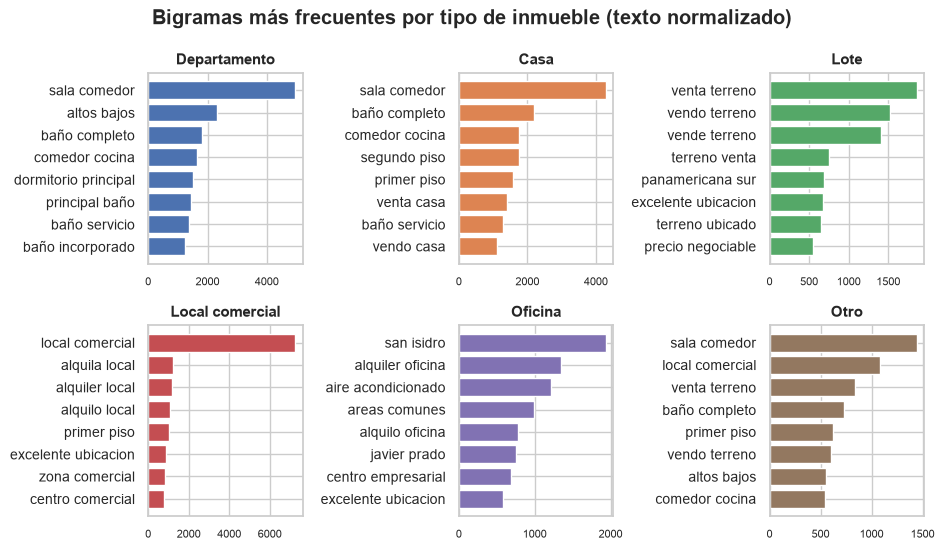

In [22]:
from sklearn.feature_extraction.text import CountVectorizer
fig, axes = plt.subplots(2, 3, figsize=(9.6, 5.6))
for ax, tp in zip(axes.ravel(), CLASES_P1 + ['Otro']):
    textos = df[df.tipo == tp].texto_norm
    textos = textos.sample(min(len(textos), 6000), random_state=SEED)
    cv = CountVectorizer(ngram_range=(2, 2), token_pattern=r'(?u)\b[a-zñ][a-zñ]+\b', min_df=5)
    frec = pd.Series(np.asarray(cv.fit_transform(textos).sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    frec = frec.sort_values(ascending=False).head(8)
    ax.barh(frec.index[::-1], frec.values[::-1], color=COLORES_TIPO[tp])
    ax.set_title(tp); ax.tick_params(axis='y', labelsize=10); ax.tick_params(axis='x', labelsize=8)
plt.suptitle('Bigramas más frecuentes por tipo de inmueble (texto normalizado)', fontweight='bold')
plt.tight_layout(); guardar('fig6_bigramas'); plt.show()

Los bigramas cambian bastante según el tipo: en departamentos salen sala comedor, baño completo y dormitorio principal; en lotes venta terreno, panamericana sur y precio negociable; en oficinas alquiler oficina, aire acondicionado, San Isidro y Javier Prado. O sea que el vocabulario sí separa los tipos y un clasificador de texto debería funcionar. En "Otro" aparecen mezclados bigramas de todos los demás (sala comedor, local comercial, venta terreno), lo que hace pensar que muchos de esos avisos están mal categorizados.

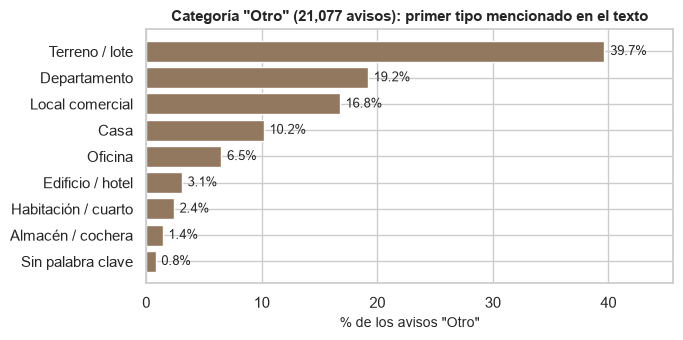

In [23]:
comp = df_otro.clave_titulo.value_counts(normalize=True).sort_values() * 100
fig, ax = plt.subplots(figsize=(6.8, 3.3))
ax.barh(comp.index, comp.values, color='#937860')
for i, v in enumerate(comp.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set(xlim=(0, comp.max() * 1.15), xlabel='% de los avisos "Otro"',
       title=f'Categoría "Otro" ({len(df_otro):,} avisos): primer tipo mencionado en el texto')
guardar('fig7_otro'); plt.show()

Viendo la primera palabra de tipo que aparece en el título, casi 40 % de los avisos "Otro" son en realidad terrenos, 19 % departamentos, 17 % locales y 10 % casas. Solo alrededor de 7 % son cosas que no están en las 5 clases (habitaciones, edificios, almacenes o cocheras) y menos de 1 % no dice nada. La gran mayoría se podría reubicar en una categoría real.

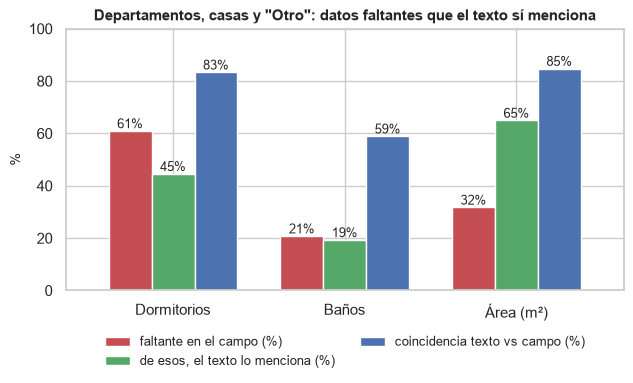

In [24]:
ax = info.iloc[:, :3].plot.bar(figsize=(7.2, 3.4), color=['#C44E52', '#55A868', '#4C72B0'], rot=0, width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt='%.0f%%', fontsize=9)
ax.set(ylim=(0, 100), ylabel='%', xlabel='', title='Departamentos, casas y "Otro": datos faltantes que el texto sí menciona')
ax.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
guardar('fig8_faltantes'); plt.show()

En departamentos, casas y "Otro", al 61 % le falta el número de dormitorios y en el 45 % de esos casos el texto lo dice de forma clara. En el área se puede completar el 65 % de lo que falta. Cuando el campo sí existe, las reglas coinciden en 83 % para dormitorios y 85 % para área, pero solo en 59 % para baños: muchos avisos describen cada baño por separado (incorporado, de visita, de servicio) y parece que el campo de Properati no los cuenta siempre igual, algo que se revisa en la sección 5.3. Esto es lo que motiva la P3.

## 5. Modelización

En la P1 y la P2 se compara una representación léxica, TF-IDF (sesión 2), con una semántica, sentence embeddings (sesión 3). En la P3 se comparan las reglas de la sección 3.3 con un LLM que devuelve los datos en JSON (sesión 5). Se usa la misma partición estratificada 80/20 con semilla 42 del trabajo parcial.

### 5.1 P1: tipo de inmueble a partir del texto

Primero los modelos lineales con TF-IDF: Naive Bayes, regresión logística y SVM.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

Xtr, Xte, ytr, yte = train_test_split(df_p1.texto_norm, df_p1.property_type, test_size=0.2,
                                      stratify=df_p1.property_type, random_state=SEED)
vec_p1 = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, max_features=200000)
A = vec_p1.fit_transform(Xtr); B = vec_p1.transform(Xte)
print('Matriz TF-IDF de entrenamiento:', A.shape)

modelos_p1 = {'Naive Bayes (Complement)': ComplementNB(alpha=0.3),
              'Regresión logística': LogisticRegression(C=5, max_iter=3000, class_weight='balanced'),
              'SVM lineal': LinearSVC(C=0.5, class_weight='balanced')}
res_p1 = []
for nombre, m in modelos_p1.items():
    t0 = time.time(); m.fit(A, ytr); pred = m.predict(B)
    res_p1.append({'modelo': 'TF-IDF + ' + nombre, 'accuracy': accuracy_score(yte, pred),
                   'F1 macro': f1_score(yte, pred, average='macro'), 'segundos': time.time() - t0})
pd.DataFrame(res_p1).round(3)

Matriz TF-IDF de entrenamiento: (65403, 200000)


,modelo,accuracy,F1 macro,segundos
0,TF-IDF + Naive Bayes (Complement),0.938,0.907,0.229
1,TF-IDF + Regresión logística,0.961,0.941,18.137
2,TF-IDF + SVM lineal,0.962,0.942,2.609


Después se calculan los embeddings de todos los avisos con el modelo multilingüe que usamos en clase (paraphrase-multilingual-MiniLM-L12-v2, 384 dimensiones). Se usa texto_modelo recortado a 1000 caracteres, porque el modelo igual corta los textos largos (en la salida se imprime hasta cuántos tokens lee). Los mismos embeddings sirven para la P1 y la P2.

In [26]:
import torch
from sentence_transformers import SentenceTransformer

dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
modelo_emb = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2', device=dispositivo)
t0 = time.time()
emb = modelo_emb.encode(df.texto_modelo.str[:1000].tolist(), batch_size=256, normalize_embeddings=True,
                        show_progress_bar=False, convert_to_numpy=True)
print(f'Embeddings de {len(df)} avisos en {time.time() - t0:.0f} s | dimensión {emb.shape[1]} | dispositivo: {dispositivo}')
print('Largo máximo que lee el modelo:', modelo_emb.max_seq_length, 'tokens')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3460.76it/s]


Embeddings de 103423 avisos en 118 s | dimensión 384 | dispositivo: cuda
Largo máximo que lee el modelo: 128 tokens


Sobre los embeddings se entrenan la regresión logística y el SVM, con las variables estandarizadas. Naive Bayes no se usa aquí porque solo acepta valores que no sean negativos, y los embeddings sí los tienen.

In [27]:
esc_p1 = StandardScaler().fit(emb[Xtr.index])
E_tr, E_te = esc_p1.transform(emb[Xtr.index]), esc_p1.transform(emb[Xte.index])
modelos_emb_p1 = {'Regresión logística': LogisticRegression(C=1, max_iter=1000, class_weight='balanced'),
                  'SVM lineal': LinearSVC(C=0.1, class_weight='balanced')}
for nombre, m in modelos_emb_p1.items():
    t0 = time.time(); m.fit(E_tr, ytr); pred = m.predict(E_te)
    res_p1.append({'modelo': 'Embeddings + ' + nombre, 'accuracy': accuracy_score(yte, pred),
                   'F1 macro': f1_score(yte, pred, average='macro'), 'segundos': time.time() - t0})
res_p1 = pd.DataFrame(res_p1).round(3)
res_p1

,modelo,accuracy,F1 macro,segundos
0,TF-IDF + Naive Bayes (Complement),0.938,0.907,0.229
1,TF-IDF + Regresión logística,0.961,0.941,18.137
2,TF-IDF + SVM lineal,0.962,0.942,2.609
3,Embeddings + Regresión logística,0.905,0.866,6.088
4,Embeddings + SVM lineal,0.916,0.878,57.964


Con TF-IDF los tres modelos funcionan bien. El SVM lineal es el mejor, con F1 macro de 0.942 y accuracy de 0.962, casi empatado con la regresión logística (0.941), y Naive Bayes queda un poco más abajo con 0.907. Con embeddings los resultados bajan: 0.878 con SVM y 0.866 con regresión logística, unos 6 puntos menos que con TF-IDF, y además calcular los embeddings de todos los avisos tomó 118 s con GPU.

En el EDA se vio que cada tipo tiene palabras muy propias, como venta terreno en los lotes o alquiler oficina en las oficinas, y TF-IDF guarda cada palabra y cada bigrama como una columna aparte. Una posible razón de la diferencia es que el embedding junta todo el aviso en un solo vector de 384 números y solo lee los primeros 128 tokens, pero eso no lo probamos. Para la P1 nos quedamos con TF-IDF + SVM lineal.

                 precision    recall  f1-score   support

           Casa      0.946     0.932     0.939      3391
   Departamento      0.988     0.987     0.987      8680
Local comercial      0.908     0.931     0.919      1402
           Lote      0.930     0.947     0.939      1887
        Oficina      0.929     0.924     0.927       991

       accuracy                          0.962     16351
      macro avg      0.940     0.944     0.942     16351
   weighted avg      0.962     0.962     0.962     16351



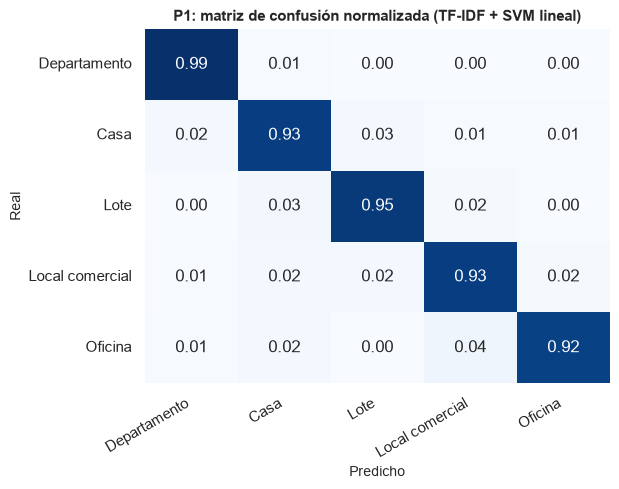

In [28]:
mejor_p1 = modelos_p1['SVM lineal']
pred = mejor_p1.predict(B)
print(classification_report(yte, pred, digits=3))
cm = confusion_matrix(yte, pred, labels=CLASES_P1, normalize='true')
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASES_P1, yticklabels=CLASES_P1, ax=ax, cbar=False)
ax.set_xlabel('Predicho'); ax.set_ylabel('Real'); ax.set_title('P1: matriz de confusión normalizada (TF-IDF + SVM lineal)')
plt.xticks(rotation=30, ha='right')
guardar('fig9_confusion_p1'); plt.show()

Casi todo cae en la diagonal. Departamento es la clase que mejor sale, con 98.7 % de recall, y los errores que más se repiten son entre casa y lote, 3 % en cada sentido, y oficinas que el modelo predice como local comercial (4 %). Local comercial es la clase con el F1 más bajo, 0.919. Estos errores parecen razonables: en la sección 2 ya salió un aviso etiquetado como Casa cuyo título dice Se vende Terreno, y el ejemplo de la sección 3.2 también es una casa que se vende como terreno. En esos casos el mismo texto habla de los dos tipos.

Ahora el modelo se aplica a los avisos "Otro", que no tienen etiqueta. Como el SVM siempre escoge una de las cinco clases, se agrega la opción "Ninguno": si el puntaje más alto del SVM queda por debajo de un umbral, el aviso no se reclasifica. El umbral se fija con el conjunto de prueba, como el valor que conserva el 95 % de las predicciones correctas. Para revisar el resultado se usa la palabra clave del título de la sección 3.4.

In [29]:
puntaje_te = mejor_p1.decision_function(B).max(axis=1)
umbral = np.quantile(puntaje_te[pred == yte.values], 0.05)
B_otro = vec_p1.transform(df_otro.texto_norm)
puntaje_otro = mejor_p1.decision_function(B_otro).max(axis=1)
df_otro['tipo_predicho'] = np.where(puntaje_otro >= umbral, mejor_p1.predict(B_otro), 'Ninguno')

MAPA_CLAVE = {'Terreno / lote': 'Lote', 'Departamento': 'Departamento', 'Casa': 'Casa',
              'Local comercial': 'Local comercial', 'Oficina': 'Oficina'}
grupo = np.where(df_otro.clave_titulo.isin(MAPA_CLAVE), 'Palabra clave de una de las 5 clases',
                 np.where(df_otro.clave_titulo == 'Sin palabra clave', 'Sin palabra clave',
                          'Palabra clave de otro tipo (habitación, edificio, almacén)'))
coincide = df_otro.clave_titulo.map(MAPA_CLAVE) == df_otro.tipo_predicho
revision = pd.DataFrame({'avisos': pd.Series(grupo).value_counts(),
                         'enviados a Ninguno (%)': pd.Series(df_otro.tipo_predicho.eq('Ninguno').values).groupby(grupo).mean() * 100,
                         'coinciden con la palabra clave (%)': pd.Series(coincide.values).groupby(grupo).mean() * 100})
revision.loc[revision.index != 'Palabra clave de una de las 5 clases', 'coinciden con la palabra clave (%)'] = np.nan
print(f'Umbral del puntaje: {umbral:.3f}')
print('Avisos "Otro" que pasan a una de las 5 clases:', (df_otro.tipo_predicho != 'Ninguno').sum(), 'de', len(df_otro))
print('Reparto de los avisos "Otro" (%):')
print((df_otro.tipo_predicho.value_counts(normalize=True) * 100).round(1).to_string())
revision.round(1)

Umbral del puntaje: 0.389
Avisos "Otro" que pasan a una de las 5 clases: 17752 de 21077
Reparto de los avisos "Otro" (%):
tipo_predicho
Lote               35.8
Departamento       19.7
Ninguno            15.8
Local comercial    14.6
Casa                8.1
Oficina             6.0


,avisos,enviados a Ninguno (%),coinciden con la palabra clave (%)
"Palabra clave de otro tipo (habitación, edificio, almacén)",1455,64.5,NaN
Palabra clave de una de las 5 clases,19451,11.5,86.6
Sin palabra clave,171,89.5,NaN


El umbral quedó en 0.389. Con eso 17 752 avisos "Otro" pasan a una de las cinco clases y el 15.8 % se queda como Ninguno. Del total de avisos "Otro", el 35.8 % pasa a lote, el 19.7 % a departamento y el 14.6 % a local comercial, parecido a lo que mostraba la palabra clave del título en la Figura 7.

La palabra clave no es una etiqueta real, pero sirve para revisar. Cuando el título nombra uno de los cinco tipos, el modelo predice ese mismo tipo en el 86.6 % de los avisos y solo el 11.5 % se va a Ninguno. En cambio, cuando el título nombra otro tipo de inmueble, como habitación, edificio o almacén, el 64.5 % se va a Ninguno, y sin palabra clave el 89.5 %. O sea que la opción Ninguno sí ayuda a separar lo que no pertenece a las cinco clases, aunque no es perfecta, porque el 35.5 % de esos avisos de otro tipo igual termina en alguna clase.

### 5.2 P2: segmento de precio a partir del texto

Se compara el texto contra modelos que solo usan datos estructurados (distrito, área, dormitorios y baños) y contra modelos que juntan ambos, para ver cuánto aporta el texto. El texto se usa con los montos enmascarados.

In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder
from scipy.sparse import hstack, csr_matrix

idx_tr, idx_te = train_test_split(df_p2.index, test_size=0.2, stratify=df_p2.segmento, random_state=SEED)
ytr2, yte2 = df_p2.loc[idx_tr, 'segmento'].astype(str), df_p2.loc[idx_te, 'segmento'].astype(str)

vec_p2 = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)
A2 = vec_p2.fit_transform(df_p2.loc[idx_tr, 'texto_norm']); B2 = vec_p2.transform(df_p2.loc[idx_te, 'texto_norm'])
lr_p2 = LogisticRegression(C=4, max_iter=3000).fit(A2, ytr2)
pred_txt = lr_p2.predict(B2)

est = df_p2[['distrito', 'area_m2', 'bedrooms', 'bathrooms']].copy()
est['distrito'] = est.distrito.astype('category').cat.codes
hgb = HistGradientBoostingClassifier(categorical_features=[0], random_state=SEED).fit(est.loc[idx_tr], ytr2)
pred_est = hgb.predict(est.loc[idx_te])

def numericas(d, ref):
    out = pd.DataFrame(index=d.index)
    for c in ['area_m2', 'bedrooms', 'bathrooms']:
        v, r = d[c], ref[c]
        if c == 'area_m2':
            v, r = np.log(v), np.log(r)
        out[c] = v.fillna(r.median())
        out[c + '_nulo'] = d[c].isna().astype(float)
    return out

tr, te = df_p2.loc[idx_tr], df_p2.loc[idx_te]
esc = StandardScaler().fit(numericas(tr, tr))
ohe = OneHotEncoder(handle_unknown='ignore').fit(tr[['distrito']].fillna('SIN DATO'))
dist_tr, dist_te = ohe.transform(tr[['distrito']].fillna('SIN DATO')), ohe.transform(te[['distrito']].fillna('SIN DATO'))
num_tr, num_te = esc.transform(numericas(tr, tr)), esc.transform(numericas(te, tr))
X_tr = hstack([A2, dist_tr, csr_matrix(num_tr)]).tocsr()
X_te = hstack([B2, dist_te, csr_matrix(num_te)]).tocsr()
lr_hib = LogisticRegression(C=4, max_iter=4000).fit(X_tr, ytr2)
pred_hib = lr_hib.predict(X_te)
lr_est = LogisticRegression(C=1, max_iter=2000).fit(hstack([dist_tr, csr_matrix(num_tr)]).tocsr(), ytr2)
pred_est_lr = lr_est.predict(hstack([dist_te, csr_matrix(num_te)]).tocsr())

esc_p2 = StandardScaler().fit(emb[idx_tr])
E2_tr, E2_te = esc_p2.transform(emb[idx_tr]), esc_p2.transform(emb[idx_te])
lr_emb_p2 = LogisticRegression(C=1, max_iter=1000).fit(E2_tr, ytr2)
pred_emb = lr_emb_p2.predict(E2_te)
lr_hib_emb = LogisticRegression(C=1, max_iter=2000).fit(np.hstack([E2_tr, dist_tr.toarray(), num_tr]), ytr2)
pred_hib_emb = lr_hib_emb.predict(np.hstack([E2_te, dist_te.toarray(), num_te]))

res_p2 = pd.DataFrame([
    {'modelo': 'Solo datos estructurados (HistGradientBoosting)', 'accuracy': accuracy_score(yte2, pred_est), 'F1 macro': f1_score(yte2, pred_est, average='macro')},
    {'modelo': 'Solo datos estructurados (regresión logística)', 'accuracy': accuracy_score(yte2, pred_est_lr), 'F1 macro': f1_score(yte2, pred_est_lr, average='macro')},
    {'modelo': 'Texto con TF-IDF + regresión logística', 'accuracy': accuracy_score(yte2, pred_txt), 'F1 macro': f1_score(yte2, pred_txt, average='macro')},
    {'modelo': 'Texto con embeddings + regresión logística', 'accuracy': accuracy_score(yte2, pred_emb), 'F1 macro': f1_score(yte2, pred_emb, average='macro')},
    {'modelo': 'TF-IDF + estructurados (regresión logística)', 'accuracy': accuracy_score(yte2, pred_hib), 'F1 macro': f1_score(yte2, pred_hib, average='macro')},
    {'modelo': 'Embeddings + estructurados (regresión logística)', 'accuracy': accuracy_score(yte2, pred_hib_emb), 'F1 macro': f1_score(yte2, pred_hib_emb, average='macro')},
]).round(3)
print('Nulos en variables estructuradas (%):', (df_p2[['distrito', 'area_m2', 'bedrooms', 'bathrooms']].isna().mean() * 100).round(1).to_dict())
res_p2

Nulos en variables estructuradas (%): {'distrito': 5.9, 'area_m2': 15.6, 'bedrooms': 52.2, 'bathrooms': 7.3}


,modelo,accuracy,F1 macro
0,Solo datos estructurados (HistGradientBoosting),0.796,0.796
1,Solo datos estructurados (regresión logística),0.774,0.773
2,Texto con TF-IDF + regresión logística,0.829,0.828
3,Texto con embeddings + regresión logística,0.631,0.626
4,TF-IDF + estructurados (regresión logística),0.867,0.866
5,Embeddings + estructurados (regresión logística),0.793,0.792


Solo con el texto, TF-IDF con regresión logística llega a 0.828 de F1 macro y le gana a los dos modelos que usan solo distrito, área, dormitorios y baños (0.796 con HistGradientBoosting y 0.773 con regresión logística). Hay que tener en cuenta que en este subconjunto esos campos tienen vacíos, por ejemplo dormitorios falta en el 52.2 % de los avisos. Lo mejor es juntar TF-IDF con los datos estructurados, que llega a 0.866, así que el texto aporta información que los campos no tienen.

Con embeddings el resultado es bastante peor: 0.626 solo con el texto y 0.792 junto con los datos estructurados. Si se compara con la misma regresión logística, agregar embeddings a los datos estructurados sube el F1 macro de 0.773 a 0.792, apenas 1.9 puntos, mientras que agregar TF-IDF lo sube a 0.866, o sea 9.3 puntos.

Para explicar qué usa el modelo se miran los coeficientes de la regresión logística con TF-IDF, que es un modelo que se puede leer directamente: cada término tiene un peso por segmento. Como entre los términos salen algunos números, también se revisa qué palabra viene después de ellos en los avisos.

              precision    recall  f1-score   support

   económico      0.853     0.872     0.862      1535
       medio      0.755     0.745     0.750      1477
        alto      0.877     0.868     0.873      1490

    accuracy                          0.829      4502
   macro avg      0.828     0.829     0.828      4502
weighted avg      0.829     0.829     0.829      4502



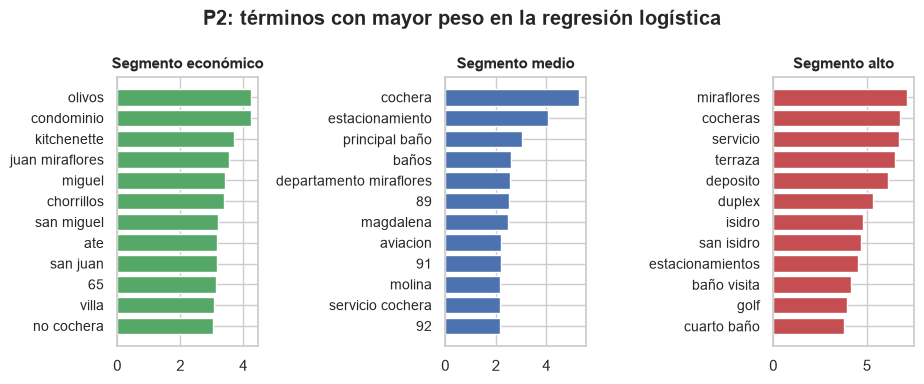

Término 65: aparece 367 veces antes de otra palabra y en 69 % de esas veces la palabra es m2


Término 92: aparece 263 veces antes de otra palabra y en 58 % de esas veces la palabra es m2


Término 91: aparece 230 veces antes de otra palabra y en 60 % de esas veces la palabra es m2


Término 89: aparece 176 veces antes de otra palabra y en 63 % de esas veces la palabra es m2


In [31]:
orden_seg = ['económico', 'medio', 'alto']
print(classification_report(yte2, pred_txt, labels=orden_seg, digits=3))
nombres = np.array(vec_p2.get_feature_names_out())
fig, axes = plt.subplots(1, 3, figsize=(9.4, 3.9))
terminos_top = []
for ax, seg in zip(axes, orden_seg):
    i = list(lr_p2.classes_).index(seg)
    top_i = np.argsort(lr_p2.coef_[i])[-12:]
    terminos_top += list(nombres[top_i])
    ax.barh(nombres[top_i], lr_p2.coef_[i][top_i], color=COLORES_SEG[seg])
    ax.set_title(f'Segmento {seg}'); ax.tick_params(axis='y', labelsize=10)
plt.suptitle('P2: términos con mayor peso en la regresión logística', fontweight='bold')
plt.tight_layout(); guardar('fig10_terminos_p2'); plt.show()
for n in [t for t in terminos_top if t.isdigit()]:
    siguiente = df_p2.texto_norm.str.findall(rf'\b{n} (\w+)').explode().dropna()
    print(f'Término {n}: aparece {len(siguiente)} veces antes de otra palabra y en {siguiente.eq("m2").mean() * 100:.0f} % de esas veces la palabra es m2')

En el reporte se ve que el segmento medio es el más difícil, con F1 de 0.750 contra 0.862 del económico y 0.873 del alto. Tiene sentido porque el medio limita con los otros dos, entonces un departamento cerca de los cortes de 125 mil o 235 mil dólares puede caer a cualquiera de los lados.

En la figura se ve que el modelo se apoya mucho en el distrito: Los Olivos, Chorrillos, San Miguel, Ate y San Juan de Miraflores empujan al económico, y Miraflores, San Isidro y golf al alto, lo mismo que mostraba el precio por m² en la Figura 4. También pesan las características de la Figura 5: cocheras en plural, terraza, depósito, dúplex y baño de visita en el alto, y no cochera o kitchenette en el económico. Los números que aparecen son más que nada áreas, porque entre el 58 % y el 69 % de las veces van seguidos de m2: 65 m2 empuja al económico y alrededor de 90 m2 al medio. Como varios términos son nombres de distritos o áreas exactas, una posible explicación de por qué los embeddings rinden menos en esta pregunta es que esos detalles se pierden al resumir el aviso en un solo vector, pero no lo comprobamos.

### 5.3 P3: dormitorios, baños y área a partir del texto

Para medir qué tan bien se predicen los datos se usan avisos donde los campos sí están llenos, así se puede comparar lo que sale del texto con el valor del campo. Se toma una muestra al azar de 300 departamentos y casas que tienen los tres campos (dormitorios, baños y área total). En el área se acepta una diferencia de hasta 5 % con el área total o con la techada, igual que en la sección 3.3.

Se comparan tres métodos:
- Reglas: las expresiones regulares de la sección 3.3.
- LLM: Qwen3-1.7B, un modelo abierto de 1.7 mil millones de parámetros que corre en la GPU de Colab. Recibe el texto con las mismas convenciones de las reglas y responde un JSON con los tres datos. Se valida que el JSON se pueda leer y que los valores sean números.
- Reglas + LLM: se usa lo que encuentran las reglas y el LLM solo completa lo que las reglas dejan vacío.

Para cada campo se miden la cobertura (en cuántos avisos el método da un valor), la precisión en lo que responde y los aciertos sobre el total de la muestra.

In [32]:
from transformers import AutoTokenizer, AutoModelForCausalLM

N_P3 = 300
base_eval = df[df.property_type.isin(['Departamento', 'Casa']) & df.bedrooms.notna() & df.bathrooms.notna() & df.surface_total.notna()]
muestra = base_eval.sample(N_P3, random_state=SEED).copy()
print('Departamentos y casas con los tres campos llenos:', len(base_eval), '| muestra:', len(muestra))

MODELO_LLM = 'Qwen/Qwen3-1.7B'
tok = AutoTokenizer.from_pretrained(MODELO_LLM)
tok.padding_side = 'left'
llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float16 if dispositivo == 'cuda' else torch.float32).to(dispositivo)
llm.eval()

INSTRUCCION = ('Extrae del aviso inmobiliario el número de dormitorios, el número de baños y el área principal del inmueble en m2. '
               'Reglas: el medio baño o baño de visita cuenta como un baño más y los baños de servicio no se cuentan; '
               'el área es la del inmueble (techada o total), no la de una terraza ni una distancia ni un precio por m2; '
               'si el aviso no lo dice o da valores distintos para varias unidades, usa null. '
               'Responde solo con un JSON así: {"dormitorios": entero o null, "banos": entero o null, "area_m2": número o null}.')

def armar_prompt(texto):
    mensajes = [{'role': 'system', 'content': 'Eres un asistente que extrae datos de avisos inmobiliarios del Perú.'},
                {'role': 'user', 'content': INSTRUCCION + '\n\nAviso: ' + texto[:1500]}]
    return tok.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True, enable_thinking=False)

def leer_json(salida):
    m = re.search(r'\{.*?\}', salida, re.S)
    if m is None:
        return None
    try:
        return json.loads(m.group(0))
    except json.JSONDecodeError:
        return None

def numero(v):
    return float(v) if isinstance(v, (int, float)) and not isinstance(v, bool) else np.nan

t0 = time.time()
salidas = []
for i in range(0, len(muestra), 8):
    lote = [armar_prompt(t) for t in muestra.texto.iloc[i:i + 8]]
    enc = tok(lote, return_tensors='pt', padding=True).to(dispositivo)
    with torch.no_grad():
        gen = llm.generate(**enc, max_new_tokens=48, do_sample=False)
    salidas += tok.batch_decode(gen[:, enc['input_ids'].shape[1]:], skip_special_tokens=True)
seg_llm = time.time() - t0

respuestas = [leer_json(s) for s in salidas]
muestra['llm_dorm'] = [numero(r.get('dormitorios')) if r else np.nan for r in respuestas]
muestra['llm_banos'] = [numero(r.get('banos')) if r else np.nan for r in respuestas]
muestra['llm_area'] = [numero(r.get('area_m2')) if r else np.nan for r in respuestas]
print(f'LLM: {len(muestra)} avisos en {seg_llm:.0f} s ({seg_llm / len(muestra):.2f} s por aviso)')
print('JSON que se pudieron leer:', sum(r is not None for r in respuestas), 'de', len(respuestas))
print('Ejemplo de respuesta:', salidas[0].strip())

Departamentos y casas con los tres campos llenos: 25863 | muestra: 300


Loading weights: 100%|██████████| 311/311 [00:02<00:00, 107.97it/s]


LLM: 300 avisos en 112 s (0.37 s por aviso)
JSON que se pudieron leer: 300 de 300
Ejemplo de respuesta: {"dormitorios": 4, "banos": 3, "area_m2": null}


In [33]:
muestra['hib_dorm'] = muestra.dorm_txt.fillna(muestra.llm_dorm)
muestra['hib_banos'] = muestra.banos_txt.fillna(muestra.llm_banos)
muestra['hib_area'] = muestra.area_txt.fillna(muestra.llm_area)

def evaluar_p3(d, metodo, col_dorm, col_banos, col_area):
    filas = []
    for campo, col in [('Dormitorios', col_dorm), ('Baños', col_banos), ('Área (m²)', col_area)]:
        v = d[col]
        if campo == 'Dormitorios':
            ok = v == d.bedrooms
        elif campo == 'Baños':
            ok = v == d.bathrooms
        else:
            ok = ((d.surface_total - v).abs() <= 0.05 * d.surface_total) | ((d.surface_covered - v).abs() <= 0.05 * d.surface_covered)
        filas.append({'campo': campo, 'método': metodo, 'cobertura (%)': v.notna().mean() * 100,
                      'precisión en lo que responde (%)': ok[v.notna()].mean() * 100,
                      'aciertos sobre el total (%)': ok.mean() * 100})
    return filas

res_p3 = pd.DataFrame(evaluar_p3(muestra, 'Reglas', 'dorm_txt', 'banos_txt', 'area_txt')
                      + evaluar_p3(muestra, 'LLM (Qwen3-1.7B)', 'llm_dorm', 'llm_banos', 'llm_area')
                      + evaluar_p3(muestra, 'Reglas + LLM', 'hib_dorm', 'hib_banos', 'hib_area'))
res_p3 = res_p3.sort_values(['campo', 'método'], key=lambda s: s.map({'Dormitorios': 0, 'Baños': 1, 'Área (m²)': 2,
                                                                       'Reglas': 0, 'LLM (Qwen3-1.7B)': 1, 'Reglas + LLM': 2})).round(1)
res_p3.set_index(['campo', 'método'])

cobertura (%)  precisión en lo que responde (%)  aciertos sobre el total (%)
campo       método                                                                                        
Dormitorios Reglas                     67.0                              85.1                         57.0
            LLM (Qwen3-1.7B)           90.7                              79.4                         72.0
            Reglas + LLM               92.0                              80.4                         74.0
Baños       Reglas                     46.3                              61.9                         28.7
            LLM (Qwen3-1.7B)           91.7                              53.5                         49.0
            Reglas + LLM               92.0                              52.5                         48.3
Área (m²)   Reglas                     52.7                              81.6                         43.0
            LLM (Qwen3-1.7B)           46.7                              79.3                         37.0
            Reglas + LLM               55.0                              81.8                         45.0

El LLM devolvió un JSON que se pudo leer en los 300 avisos. En dormitorios y baños da un valor en más del 90 % de los avisos, mientras que las reglas solo en el 67.0 % y el 46.3 %. Cuando responde acierta un poco menos que las reglas (79.4 % contra 85.1 % en dormitorios y 53.5 % contra 61.9 % en baños), pero como responde muchos más avisos, sobre el total acierta más: 72.0 % contra 57.0 % en dormitorios y 49.0 % contra 28.7 % en baños. La combinación Reglas + LLM es la mejor en dormitorios con 74.0 % y en área con 45.0 %, y en baños queda casi igual que el LLM solo, 48.3 % contra 49.0 %.

En el área pasa lo contrario: el LLM responde en menos avisos que las reglas, 46.7 % contra 52.7 %, con una precisión parecida, así que ahí las reglas funcionan mejor y el LLM solo completa unos pocos casos. También hay que ver el costo: el LLM tardó 112 s para 300 avisos, mientras que las reglas procesaron los 103 mil avisos en 24 s en la sección 3.3. Por eso tiene más sentido usar el LLM solo en los avisos donde las reglas no encuentran nada, que es lo que hace la combinación.

In [34]:
con_reglas = muestra.banos_txt.notna()
print('Avisos donde las reglas encuentran los baños:', con_reglas.sum())
print(f'En esos avisos aciertan las reglas en {(muestra.banos_txt == muestra.bathrooms)[con_reglas].mean() * 100:.1f} % '
      f'y el LLM en {(muestra.llm_banos == muestra.bathrooms)[con_reglas].mean() * 100:.1f} %')
dif = (muestra.llm_banos - muestra.bathrooms)[muestra.llm_banos.notna() & (muestra.llm_banos != muestra.bathrooms)]
print(f'Avisos donde el LLM no coincide con el campo de baños: {len(dif)}, de ellos {dif.abs().eq(1).sum()} por un solo baño')

especial = muestra.texto.str.lower().str.contains(r'\bba[ñn]?os? (?:completos? )?(?:de |para )?(?:servicio|visitas?)\b|\bmedio ba[ñn]?o\b|1/2 ba[ñn]?o|\by medio\b|toilette')
filas = {}
for nombre, grupo in [('Menciona baño de servicio, de visita o medio baño', especial), ('No menciona esos baños', ~especial)]:
    filas[nombre] = {'avisos': grupo.sum(),
                     'precisión de las reglas (%)': (muestra.banos_txt == muestra.bathrooms)[grupo & muestra.banos_txt.notna()].mean() * 100,
                     'precisión del LLM (%)': (muestra.llm_banos == muestra.bathrooms)[grupo & muestra.llm_banos.notna()].mean() * 100}
pd.DataFrame.from_dict(filas, orient='index').round(1)

Avisos donde las reglas encuentran los baños: 139
En esos avisos aciertan las reglas en 61.9 % y el LLM en 63.3 %
Avisos donde el LLM no coincide con el campo de baños: 128, de ellos 92 por un solo baño


,avisos,precisión de las reglas (%),precisión del LLM (%)
"Menciona baño de servicio, de visita o medio baño",133,45.5,41.9
No menciona esos baños,167,72.6,63.7


Para entender por qué baños sale tan bajo se revisaron dos cosas. Primero, en los 139 avisos donde las reglas encuentran los baños, las reglas aciertan el 61.9 % y el LLM el 63.3 %, o sea que sobre los mismos avisos el LLM no es peor. Su precisión general es menor porque también responde los avisos donde las reglas no dicen nada, que parecen ser más difíciles.

Segundo, la precisión de los dos métodos baja bastante cuando el aviso menciona baño de servicio, de visita o medio baño: 45.5 % las reglas y 41.9 % el LLM, contra 72.6 % y 63.7 % cuando no los menciona. Además, 92 de los 128 desacuerdos del LLM con el campo son por un solo baño. Esto cuadra con la sección 3.3, donde el texto y el campo de baños solo coincidían en el 58.9 %. Parece que el campo de Properati no siempre cuenta esos baños de la misma forma, así que parte del error podría estar en la referencia y no en el método. No lo podemos asegurar sin revisar avisos a mano, por eso el resultado de baños hay que tomarlo con cuidado.

## 6. Publicación de los resultados

La tabla junta el mejor resultado de cada pregunta y la figura compara todos los modelos, con las métricas del conjunto de prueba en la P1 y la P2 y de la muestra evaluada en la P3.

In [35]:
mejor_p1_fila = res_p1.loc[res_p1['F1 macro'].idxmax()]
mejor_p2_fila = res_p2.loc[res_p2['F1 macro'].idxmax()]
mejor_txt_p2 = res_p2[~res_p2.modelo.str.contains('estructurados')].sort_values('F1 macro').iloc[-1]
p3_total = res_p3.pivot(index='método', columns='campo', values='aciertos sobre el total (%)')
resumen_resultados = pd.DataFrame([
    {'pregunta': 'P1: tipo de inmueble', 'mejor modelo': mejor_p1_fila.modelo, 'métrica': 'F1 macro', 'valor': mejor_p1_fila['F1 macro']},
    {'pregunta': 'P2: segmento de precio (solo texto)', 'mejor modelo': mejor_txt_p2.modelo, 'métrica': 'F1 macro', 'valor': mejor_txt_p2['F1 macro']},
    {'pregunta': 'P2: segmento de precio (texto + estructurados)', 'mejor modelo': mejor_p2_fila.modelo, 'métrica': 'F1 macro', 'valor': mejor_p2_fila['F1 macro']},
] + [{'pregunta': f'P3: {campo.lower()}', 'mejor modelo': p3_total[campo].idxmax(), 'métrica': 'aciertos sobre el total (%)',
      'valor': p3_total[campo].max()} for campo in ['Dormitorios', 'Baños', 'Área (m²)']])
resumen_resultados

,pregunta,mejor modelo,métrica,valor
0,P1: tipo de inmueble,TF-IDF + SVM lineal,F1 macro,0.942
1,P2: segmento de precio (solo texto),Texto con TF-IDF + regresión logística,F1 macro,0.828
2,P2: segmento de precio (texto + estructurados),TF-IDF + estructurados (regresión logística),F1 macro,0.866
3,P3: dormitorios,Reglas + LLM,aciertos sobre el total (%),74.000
4,P3: baños,LLM (Qwen3-1.7B),aciertos sobre el total (%),49.000
5,P3: área (m²),Reglas + LLM,aciertos sobre el total (%),45.000


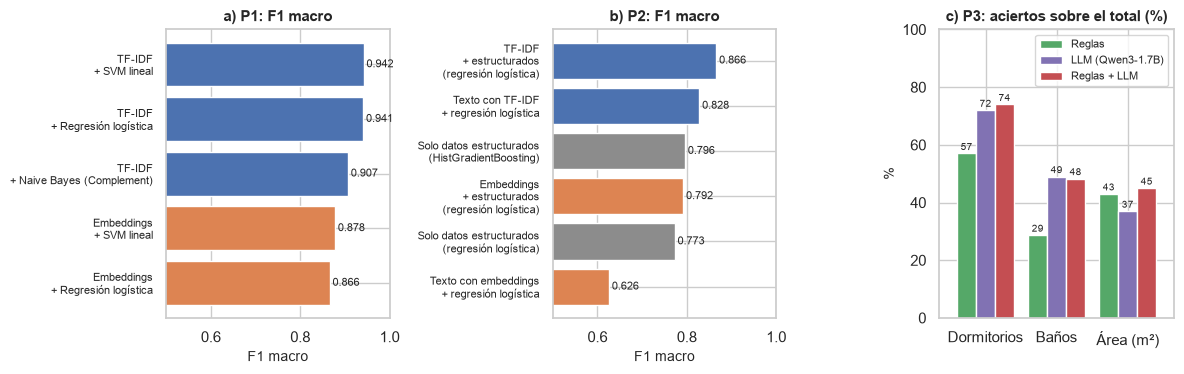

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), gridspec_kw={'width_ratios': [1, 1, 1.05]})
r1 = res_p1.sort_values('F1 macro')
axes[0].barh(r1.modelo.str.replace(' + ', '\n+ ', regex=False), r1['F1 macro'],
             color=['#4C72B0' if m.startswith('TF-IDF') else '#DD8452' for m in r1.modelo])
axes[0].set(xlim=(0.5, 1), title='a) P1: F1 macro', xlabel='F1 macro')
r2 = res_p2.sort_values('F1 macro')
axes[1].barh(r2.modelo.str.replace(' (', '\n(', regex=False).str.replace(' + ', '\n+ ', regex=False), r2['F1 macro'],
             color=['#8C8C8C' if m.startswith('Solo') else ('#4C72B0' if 'TF-IDF' in m else '#DD8452') for m in r2.modelo])
axes[1].set(xlim=(0.5, 1), title='b) P2: F1 macro', xlabel='F1 macro')
for ax in axes[:2]:
    ax.bar_label(ax.containers[0], fmt='%.3f', fontsize=8, padding=2)
    ax.tick_params(axis='y', labelsize=8)
metodos = ['Reglas', 'LLM (Qwen3-1.7B)', 'Reglas + LLM']
p3_total.loc[metodos, ['Dormitorios', 'Baños', 'Área (m²)']].T.plot.bar(ax=axes[2], rot=0, width=0.8, color=['#55A868', '#8172B3', '#C44E52'])
for barras in axes[2].containers:
    axes[2].bar_label(barras, fmt='%.0f', fontsize=7, padding=1)
axes[2].set(ylim=(0, 100), title='c) P3: aciertos sobre el total (%)', ylabel='%', xlabel='')
axes[2].legend(fontsize=8, loc='upper right')
plt.tight_layout(); guardar('fig11_resultados'); plt.show()

En la P1, TF-IDF + SVM lineal llega a 0.942 de F1 macro. En la P2, el texto solo llega a 0.828 y junto con los datos estructurados a 0.866. En la P3 los mejores aciertos sobre el total son 74.0 % en dormitorios y 45.0 % en área con Reglas + LLM, y 49.0 % en baños con el LLM solo. En la figura se ve que en las dos preguntas de clasificación TF-IDF quedó por encima de los embeddings, y que en la P3 el LLM sube bastante los aciertos de dormitorios y baños pero no los de área.

## 7. Dataset final

Se guarda el dataset limpio (sin duplicados, con textos anonimizados y normalizados, las variables derivadas y el tipo predicho para los avisos "Otro") en la carpeta data. También se guarda la muestra de la P3 con las respuestas de las reglas y del LLM.

In [37]:
df['tipo_predicho'] = df_otro['tipo_predicho']
cols_final = ['id', 'start_date', 'end_date', 'created_on', 'lat', 'lon', 'region', 'provincia', 'distrito', 'es_lima_metro',
              'property_type', 'tipo_predicho', 'operation_type', 'price', 'currency', 'price_period', 'surface_total', 'surface_covered',
              'bedrooms', 'bathrooms', 'texto_modelo', 'texto_norm', 'n_palabras', 'dorm_txt', 'banos_txt', 'area_txt',
              'area_techada_txt', 'area_terreno_txt', 'segmento_precio'] + ['am_' + a for a in AMENIDADES]
final = df[cols_final].copy()
final.to_csv('data/avisos_pe_limpio.csv.xz', index=False, compression='xz')
muestra[['id', 'bedrooms', 'bathrooms', 'surface_total', 'surface_covered', 'dorm_txt', 'banos_txt', 'area_txt',
         'llm_dorm', 'llm_banos', 'llm_area', 'hib_dorm', 'hib_banos', 'hib_area']].to_csv('data/p3_muestra_reglas_llm.csv', index=False)
print('Dataset final:', final.shape, '| tamaño:', round(os.path.getsize('data/avisos_pe_limpio.csv.xz') / 1e6, 1), 'MB')
final.head(3)

Dataset final: (103423, 41) | tamaño: 25.9 MB


,id,start_date,end_date,created_on,lat,lon,region,provincia,distrito,es_lima_metro,...,am_ascensor,am_cochera o estacionamiento,am_terraza,am_vista al mar / malecón,am_estreno,am_zona de parrilla,am_vigilancia,am_amoblado,am_jardín,am_áreas comunes
0,OHnwRj8WCByyWFlzr8CG2w==,2019-06-25,2019-07-23,2019-06-25,-12.094636,-77.003267,Lima,Lima,San Borja,True,...,False,True,True,False,False,False,False,False,False,False
1,+r81Zjmgyd2Y+cguWfoHhw==,2019-06-25,2019-12-25,2019-06-25,-12.094851,-77.017706,Lima,Lima,San Isidro,True,...,False,True,True,False,False,False,False,True,True,False
2,TP2j5KyjkY1glXvrCBoqkA==,2019-06-25,2019-09-03,2019-06-25,-12.071644,-77.037922,Lima,Lima,Jesús María,True,...,False,False,False,False,False,False,False,False,False,False


## 8. Conclusiones

En este trabajo se aplicó minería de textos a 103 423 avisos inmobiliarios del Perú, después de quitar duplicados, HTML y datos personales y de enmascarar los montos escritos. En la P1, TF-IDF con un SVM lineal identifica el tipo de inmueble con F1 macro de 0.942 y, con un umbral sobre su puntaje, se reclasificaron 17 752 avisos "Otro" en una de las cinco clases, dejando como Ninguno a los que no se parecen a ninguna. En la P2 el texto solo predice el segmento de precio con F1 macro de 0.828 y junto con los datos estructurados llega a 0.866; los coeficientes muestran que pesan sobre todo el distrito, la cochera, la terraza y el área. En las dos preguntas los sentence embeddings quedaron por debajo de TF-IDF, un resultado negativo para ese enfoque con estos datos. En la P3 el LLM Qwen3-1.7B devolvió JSON válido en todos los avisos y junto con las reglas subió los aciertos de dormitorios de 57.0 % a 74.0 %, aunque en baños el resultado sigue bajo (49.0 %) y parece que el campo de referencia no cuenta igual los baños de servicio o de visita. Como trabajo futuro quedan etiquetar a mano una muestra para evaluar mejor la P3, probar un modelo que lea textos más largos o con ajuste fino, y construir el buscador semántico que se planteó en el trabajo parcial.